# Minor Project 3: Logistic Regression Project Report
**Project Name:** Diabetes Prediction using Kaggle Data  
**Student Name:** Vansh Modi

### Objective:
Predict binary diabetes outcome **(0 = No Diabetes, 1 = Diabetes)** using patient clinical measurements from the Pima Indians Diabetes Database.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [30]:
# Load the dataset
df = pd.read_csv('diabetes.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1. Data Inspection & Cleaning
In the Pima Indians Diabetes dataset, biological measurements such as Glucose, BloodPressure, SkinThickness, Insulin, and BMI cannot biologically be zero. These zero values represent missing observations and are replaced with **NaN** before imputation to avoid skewing summary statistics.

In [31]:
# Identify biological features where zero indicates missing data
zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

In [32]:
# Count zeros in these columns before replacement
print("Zero counts before replacement:")
print((df[zero_features] == 0).sum())

Zero counts before replacement:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [33]:
# Replace zeros with NaN
df[zero_features] = df[zero_features].replace(0, np.nan)

In [34]:
# Separate features and target
X = df.drop(columns=['Outcome'])
y = df['Outcome']

## 2. Train-Test Split & Preprocessing Pipeline
* To prevent data leakage, the dataset is split into training (80%) and testing (20%) sets prior to imputation and scaling, with stratification enabled to preserve the outcome class ratio.

* Missing values are imputed using the **median** of the training distribution, followed by feature standardization using **StandardScaler**.

In [35]:
# 80-20 Train-Test Split with stratification to preserve outcome ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples (Actual 0: {(y_test == 0).sum()}, Actual 1: {(y_test == 1).sum()})")

Training set size: 614 samples
Test set size: 154 samples (Actual 0: 100, Actual 1: 54)


In [36]:
# Median Imputation (fit on train, transform on both)
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [37]:
# Standardization (fit on train, transform on both)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [38]:
# Retain column names for coefficient interpretation
feature_names = X.columns

## 3. Model Training
A Logistic Regression classifier is trained using **class_weight='balanced'**. This assigns higher penalties to misclassifying the minority positive class, effectively balancing precision and recall.

In [39]:
# Train Logistic Regression with balanced weights
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)
print("Model training complete.")

Model training complete.


## 4. Model Evaluation & Visualization
Performance is evaluated on the unseen test set (154 samples). Because false negatives represent missed diagnoses in a medical screening context, recall is prioritized alongside overall ROC-AUC discrimination.

In [40]:
# Predict classes and probability estimates
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [41]:
# Calculate metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
print(f"Accuracy  : {acc:.3f}")
print(f"Precision : {prec:.3f}")
print(f"Recall    : {rec:.3f}")
print(f"F1-Score  : {f1:.3f}")
print(f"ROC-AUC   : {roc_auc:.3f}")

Accuracy  : 0.734
Precision : 0.603
Recall    : 0.704
F1-Score  : 0.650
ROC-AUC   : 0.813


In [42]:
# Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix:\nTN={tn}, FP={fp}\nFN={fn}, TP={tp}")


Confusion Matrix:
TN=75, FP=25
FN=16, TP=38


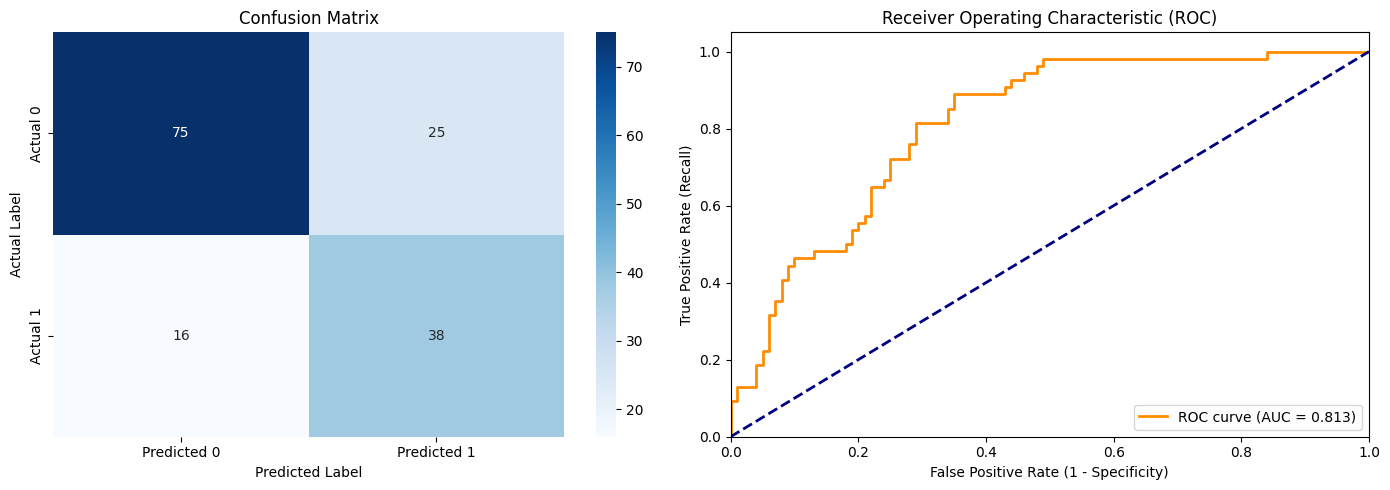

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Feature Importance & Coefficient Interpretation
Standardized model coefficients quantify the log-odds impact of each feature on predicting a positive diabetes outcome.

In [44]:
# Coefficients extraction
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

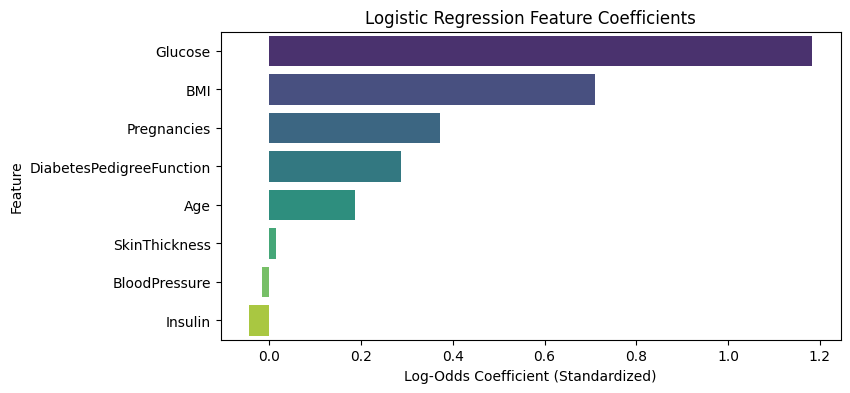

                 Feature  Coefficient
                 Glucose     1.183483
                     BMI     0.709592
             Pregnancies     0.372902
DiabetesPedigreeFunction     0.287734
                     Age     0.186434
           SkinThickness     0.013980
           BloodPressure    -0.014612
                 Insulin    -0.044609


In [45]:
# Plot coefficients
plt.figure(figsize=(8, 4))
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=coef_df,
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Log-Odds Coefficient (Standardized)')
plt.show()
print(coef_df.to_string(index=False))

## 6. Key Findings, Limitations & Conclusion

### Key Findings:
- The model obtains an **ROC-AUC of 0.813** and achieves a **Recall of 70.4%** on the fixed test split.
- **Glucose** and **BMI** have the highest positive coefficients, confirming they are the primary driving predictors of diabetes risk in this cohort.
- Balanced weighting prevents the classifier from biasing heavily toward the non-diabetic majority class.

### Limitations:
- The dataset is derived from a specific historical cohort of Pima Native American females. It serves educational benchmarking purposes and should not be used as a stand-alone clinical diagnostic tool.

### Conclusion:
The logistic regression pipeline successfully classifies diabetes outcomes with an accuracy of 73.4% and an F1-score of 0.650. By replacing invalid zeros, applying median imputation, and standardizing features, data contamination was prevented while maintaining model interpretability.